In [8]:
import torch
import gpytorch

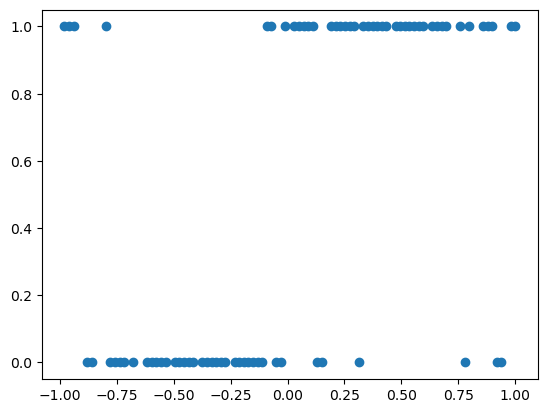

In [23]:
from tqdm import tqdm
import math
import torch
import gpytorch
from matplotlib import pyplot as plt

# Make plots inline
%matplotlib inline

import os
from math import floor

# this is for running the notebook in our testing framework
smoke_test = ('CI' in os.environ)

N = 100
X = torch.linspace(-1., 1., N)
probs = (torch.sin(X * math.pi).add(1.).div(2.))
y = torch.distributions.Bernoulli(probs=probs).sample()
X = X.unsqueeze(-1)

train_n = int(floor(0.8 * N))
indices = torch.randperm(N)
train_x = X[indices[:train_n]].contiguous()
train_y = y[indices[:train_n]].contiguous()

test_x = X[indices[train_n:]].contiguous()
test_y = y[indices[train_n:]].contiguous()

if torch.cuda.is_available():
    train_x, train_y, test_x, test_y = train_x.cuda(), train_y.cuda(), test_x.cuda(), test_y.cuda()
    
plt.plot(train_x.squeeze(-1).cpu(), train_y.cpu(), 'o')

from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(train_x, train_y)
train_loader = DataLoader(train_dataset, batch_size=100000, shuffle=False)

test_dataset = TensorDataset(test_x, test_y)
test_loader = DataLoader(test_dataset, batch_size=1024, shuffle=False)

class PGLikelihood(gpytorch.likelihoods._OneDimensionalLikelihood):
    # this method effectively computes the expected log likelihood
    # contribution to Eqn (10) in Reference [1].
    def expected_log_prob(self, target, input, *args, **kwargs):
        mean, variance = input.mean, input.variance
        # Compute the expectation E[f_i^2]
        raw_second_moment = variance + mean.pow(2)

        # Translate targets to be -1, 1
        target = target.to(mean.dtype).mul(2.).sub(1.)

        # We detach the following variable since we do not want
        # to differentiate through the closed-form PG update.
        c = raw_second_moment.detach().sqrt()
        # Compute mean of PG auxiliary variable omega: 0.5 * Expectation[omega]
        # See Eqn (11) and Appendix A2 and A3 in Reference [1] for details.
        half_omega = 0.25 * torch.tanh(0.5 * c) / c

        # Expected log likelihood
        res = 0.5 * target * mean - half_omega * raw_second_moment
        # Sum over data points in mini-batch
        res = res.sum(dim=-1)

        return res

    # define the likelihood
    def forward(self, function_samples):
        return torch.distributions.Bernoulli(logits=function_samples)

    # define the marginal likelihood using Gauss Hermite quadrature
    def marginal(self, function_dist):
        prob_lambda = lambda function_samples: self.forward(function_samples).probs
        probs = self.quadrature(prob_lambda, function_dist)
        return torch.distributions.Bernoulli(probs=probs)


# define the actual GP model (kernels, inducing points, etc.)
class GPModel(gpytorch.models.ApproximateGP):
    def __init__(self, inducing_points):
        variational_distribution = gpytorch.variational.NaturalVariationalDistribution(inducing_points.size(0))
        variational_strategy = gpytorch.variational.VariationalStrategy(
            self, inducing_points, variational_distribution, learn_inducing_locations=True
        )
        super(GPModel, self).__init__(variational_strategy)
        self.mean_module = gpytorch.means.ZeroMean()
        self.covar_module = gpytorch.kernels.ScaleKernel(gpytorch.kernels.RBFKernel())

    def forward(self, x):
        mean_x = self.mean_module(x)
        covar_x = self.covar_module(x)
        return gpytorch.distributions.MultivariateNormal(mean_x, covar_x)

# we initialize our model with M = 30 inducing points
M = 30
inducing_points = torch.linspace(-2., 2., M, dtype=train_x.dtype, device=train_x.device).unsqueeze(-1)
model = GPModel(inducing_points=inducing_points)
model.covar_module.base_kernel.initialize(lengthscale=0.2)
likelihood = PGLikelihood()

if torch.cuda.is_available():
    model = model.cuda()
    likelihood = likelihood.cuda()
    
variational_ngd_optimizer = gpytorch.optim.NGD(model.variational_parameters(), num_data=train_y.size(0), lr=0.1)

hyperparameter_optimizer = torch.optim.Adam([
    {'params': model.hyperparameters()},
    {'params': likelihood.parameters()},
], lr=0.01)

model.train()
likelihood.train()
mll = gpytorch.mlls.VariationalELBO(likelihood, model, num_data=train_y.size(0))

num_epochs = 1 if smoke_test else 100


In [25]:
#epochs_iter = tqdm.notebook.tqdm(range(num_epochs), desc="Epoch")
for i in tqdm(range(num_epochs)):
    #minibatch_iter = tqdm.notebook.tqdm(train_loader, desc="Minibatch", leave=False)

    for x_batch, y_batch in tqdm(train_loader, desc="Minibatch", leave=False):
        ### Perform NGD step to optimize variational parameters
        variational_ngd_optimizer.zero_grad()
        hyperparameter_optimizer.zero_grad()

        output = model(x_batch)
        loss = -mll(output, y_batch)
        #minibatch_iter.set_postfix(loss=loss.item())
        loss.backward()
        variational_ngd_optimizer.step()
        hyperparameter_optimizer.step()

Minibatch:   0%|                                          | 0/1 [00:00<?, ?it/s]
                                                                                
Minibatch:   0%|                                          | 0/1 [00:00<?, ?it/s]
                                                                                
Minibatch:   0%|                                          | 0/1 [00:00<?, ?it/s]
                                                                                
Minibatch:   0%|                                          | 0/1 [00:00<?, ?it/s]
                                                                                
Minibatch:   0%|                                          | 0/1 [00:00<?, ?it/s]
                                                                                
Minibatch:   0%|                                          | 0/1 [00:00<?, ?it/s]
                                                                                
Minibatch:   0%|            

Minibatch:   0%|                                          | 0/1 [00:00<?, ?it/s]
                                                                                
Minibatch:   0%|                                          | 0/1 [00:00<?, ?it/s]
                                                                                
100%|█████████████████████████████████████████| 100/100 [00:01<00:00, 72.61it/s]


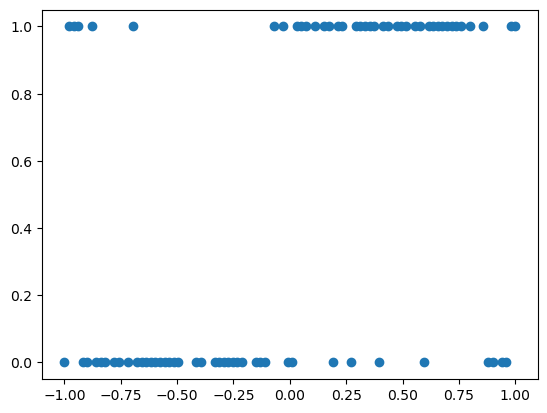

In [26]:
model.

GPModel(
  (variational_strategy): VariationalStrategy(
    (_variational_distribution): NaturalVariationalDistribution()
  )
  (mean_module): ZeroMean()
  (covar_module): ScaleKernel(
    (base_kernel): RBFKernel(
      (raw_lengthscale_constraint): Positive()
    )
    (raw_outputscale_constraint): Positive()
  )
)

ImportError: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html